# YOLOv11 Training with Custom Dataset on Local System

**NOTE!** Notebook ini dibuat khusus untuk spesifikasi sistem berikut ini:
- NVIDIA RTX 3050 6GB Laptop GPU
- 16 GB RAM DDR4 Single Channel
- CachyOS Linux (Arch-based) with fish shell.

Kalau ingin dijalankan di selain sistem ini, pastikan untuk menyesuaikan beberapa perintah yang digunakan.

**JALANIN TIAP SEL DISINI HARUS URUT, KALAU ENGGA BAKAL ERROR** (kecuali step 0 dan 1, cukup jalanin di awal setup aja)


## 0. Environment Setup

In [ ]:
!python -m venv ~/yolo-env
!source ~/yolo-env/bin/activate.fish
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
!pip install ultralytics ipykernel matplotlib pandas seaborn opencv-python

Pastikan driver NVIDIA sudah terpasang dan `nvidia-smi` berjalan (di CachyOS biasanya lewat `chwd` atau paket `nvidia-open`/`nvidia-dkms`). Toolkit CUDA sistem tidak diperlukan karena wheel PyTorch sudah membawa runtime CUDA sendiri.

Untuk download dependensi sendiri akan memakan storage yang cukup banyak dan waktu yang lama, pastikan kamu punya storage yang banyak dan koneksi internet yang stabil dan cepat.

Nantinya akan ada ada pilihan untuk memilih kernel yang akan digunakan, pilih kernel **yolo-env** di notebook ini.

## 1. Cek GPU dan environment

In [22]:
!nvidia-smi
!chwd

Sun Oct 25 12:09:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.78.08              KMD Version: 615.78.08     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   50C    P8              6W /   60W |    1242MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
import torch
import ultralytics

print('PyTorch     :', torch.__version__)
print('CUDA tersedia:', torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print('GPU         :', props.name)
    print(f'VRAM        : {props.total_memory / 1024**3:.1f} GB')
ultralytics.checks()

Ultralytics 8.4.187 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)
Setup complete ✅ (16 CPUs, 15.3 GB RAM, 86.7/197.5 GB disk)


## 2. Konfigurasi dataset

Struktur folder yang diharapkan (format YOLO, koordinat ter-normalisasi):

```
dataset/
├── images/
│   ├── train/
│   └── val/
└── labels/
    ├── train/
    └── val/
```

Jika gambar dan label masih dalam satu folder datar (belum dipisah train/val), isi `RAW_IMAGES` dan `RAW_LABELS` lalu set `SPLIT_DATASET = True` pada sel berikutnya.

In [3]:
from pathlib import Path

# === SESUAIKAN ===
DATASET_DIR = Path('./datasets/MRI-Tumor-Dataset').resolve()
CLASS_NAMES = ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor']

SPLIT_DATASET = False                      # True jika data masih datar dan perlu dibagi train/val
RAW_IMAGES = Path('./raw/images').resolve()
RAW_LABELS = Path('./raw/labels').resolve()
VAL_RATIO = 0.2
# =================

print('Dataset:', DATASET_DIR)

Dataset: /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset


## 3. (Opsional) Bagi dataset menjadi train dan val

In [ ]:
import random
import shutil

if SPLIT_DATASET:
    random.seed(42)
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    images = sorted(p for p in RAW_IMAGES.iterdir() if p.suffix.lower() in exts)
    random.shuffle(images)

    n_val = int(len(images) * VAL_RATIO)
    splits = {'val': images[:n_val], 'train': images[n_val:]}

    for split, files in splits.items():
        (DATASET_DIR / 'images' / split).mkdir(parents=True, exist_ok=True)
        (DATASET_DIR / 'labels' / split).mkdir(parents=True, exist_ok=True)
        for img in files:
            shutil.copy2(img, DATASET_DIR / 'images' / split / img.name)
            lbl = RAW_LABELS / f'{img.stem}.txt'
            if lbl.exists():
                shutil.copy2(lbl, DATASET_DIR / 'labels' / split / lbl.name)
        print(f'{split}: {len(files)} gambar')
else:
    print('Split dilewati (SPLIT_DATASET = False).')

## 4. Buat `data.yaml` dan cek jumlah data

**NOTE!** Pastikan struktur datasetnya seperti pada Langkah No. 2.

In [4]:
import yaml

data_cfg = {
    'path': str(DATASET_DIR),
    'train': str(DATASET_DIR / 'images' / 'train'),
    'val': str(DATASET_DIR / 'images' / 'val'),
    'nc': len(CLASS_NAMES),
    'names': CLASS_NAMES,
}

DATA_YAML = DATASET_DIR / 'data.yaml'
DATASET_DIR.mkdir(parents=True, exist_ok=True)
with open(DATA_YAML, 'w') as f:
    yaml.dump(data_cfg, f, sort_keys=False)
print(DATA_YAML.read_text())

for split in ['train', 'val']:
    img_dir = DATASET_DIR / 'images' / split
    lbl_dir = DATASET_DIR / 'labels' / split
    n_img = len(list(img_dir.glob('*'))) if img_dir.exists() else 0
    n_lbl = len(list(lbl_dir.glob('*.txt'))) if lbl_dir.exists() else 0
    print(f'{split}: {n_img} gambar, {n_lbl} label')

path: /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset
train: /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/train
val: /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val
nc: 4
names:
- Glioma
- Meningioma
- Pituitary
- No Tumor

train: 1695 gambar, 1695 label
val: 502 gambar, 502 label


## 5. Training

Pengaturan untuk RTX 3050 6GB: `yolo11s` dengan `batch=8` pada `imgsz=640` biasanya muat. Jika terjadi CUDA out of memory, turunkan `batch` ke 4 atau ganti ke `yolo11n.pt`. Jika VRAM masih longgar, coba `batch=16` atau `yolo11m.pt`.

`cache='ram'` mempercepat training jika RAM cukup untuk menampung dataset; ubah ke `False` jika dataset besar.

Sebelum mulai training, **TUTUP APLIKASI YANG BERJALAN DI BACKGROUND**, karena proses training bakal makan banyak RAM.

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11s.pt')  # bobot pretrained COCO, diunduh otomatis saat pertama kali

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    cache='ram',
    amp=True,
    lr0=0.001,
    lrf=0.001,
    patience=20,
    project=str(Path('./runs').resolve()),
    name='custom_yolo11',
    exist_ok=True,
    plots=True,
)

New https://pypi.org/project/ultralytics/8.4.188 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.187 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask

## 6. Lihat hasil training

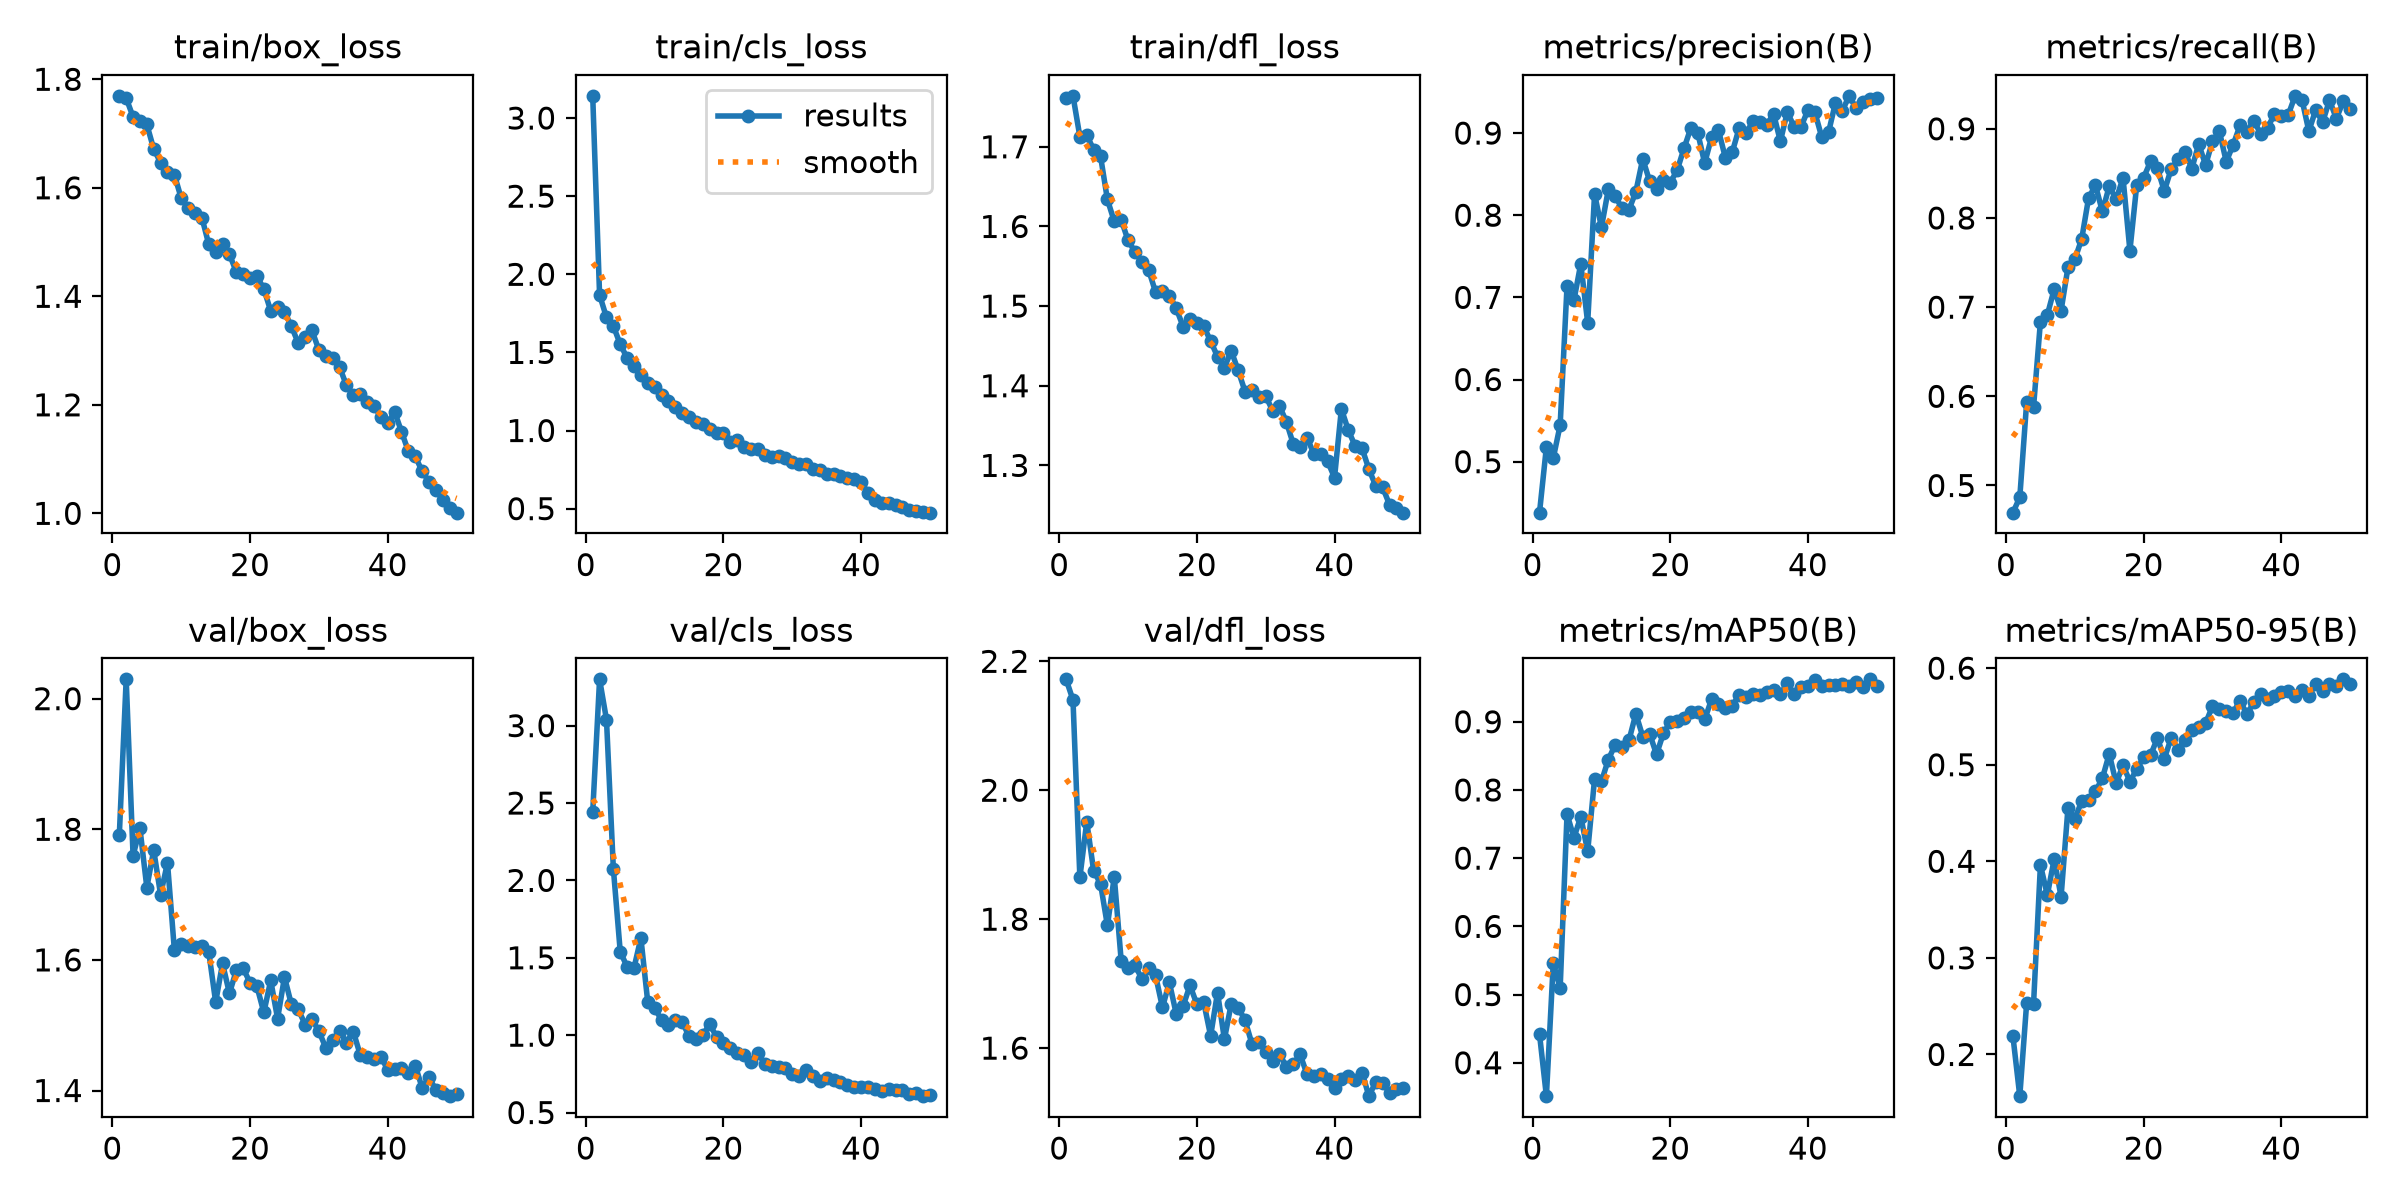

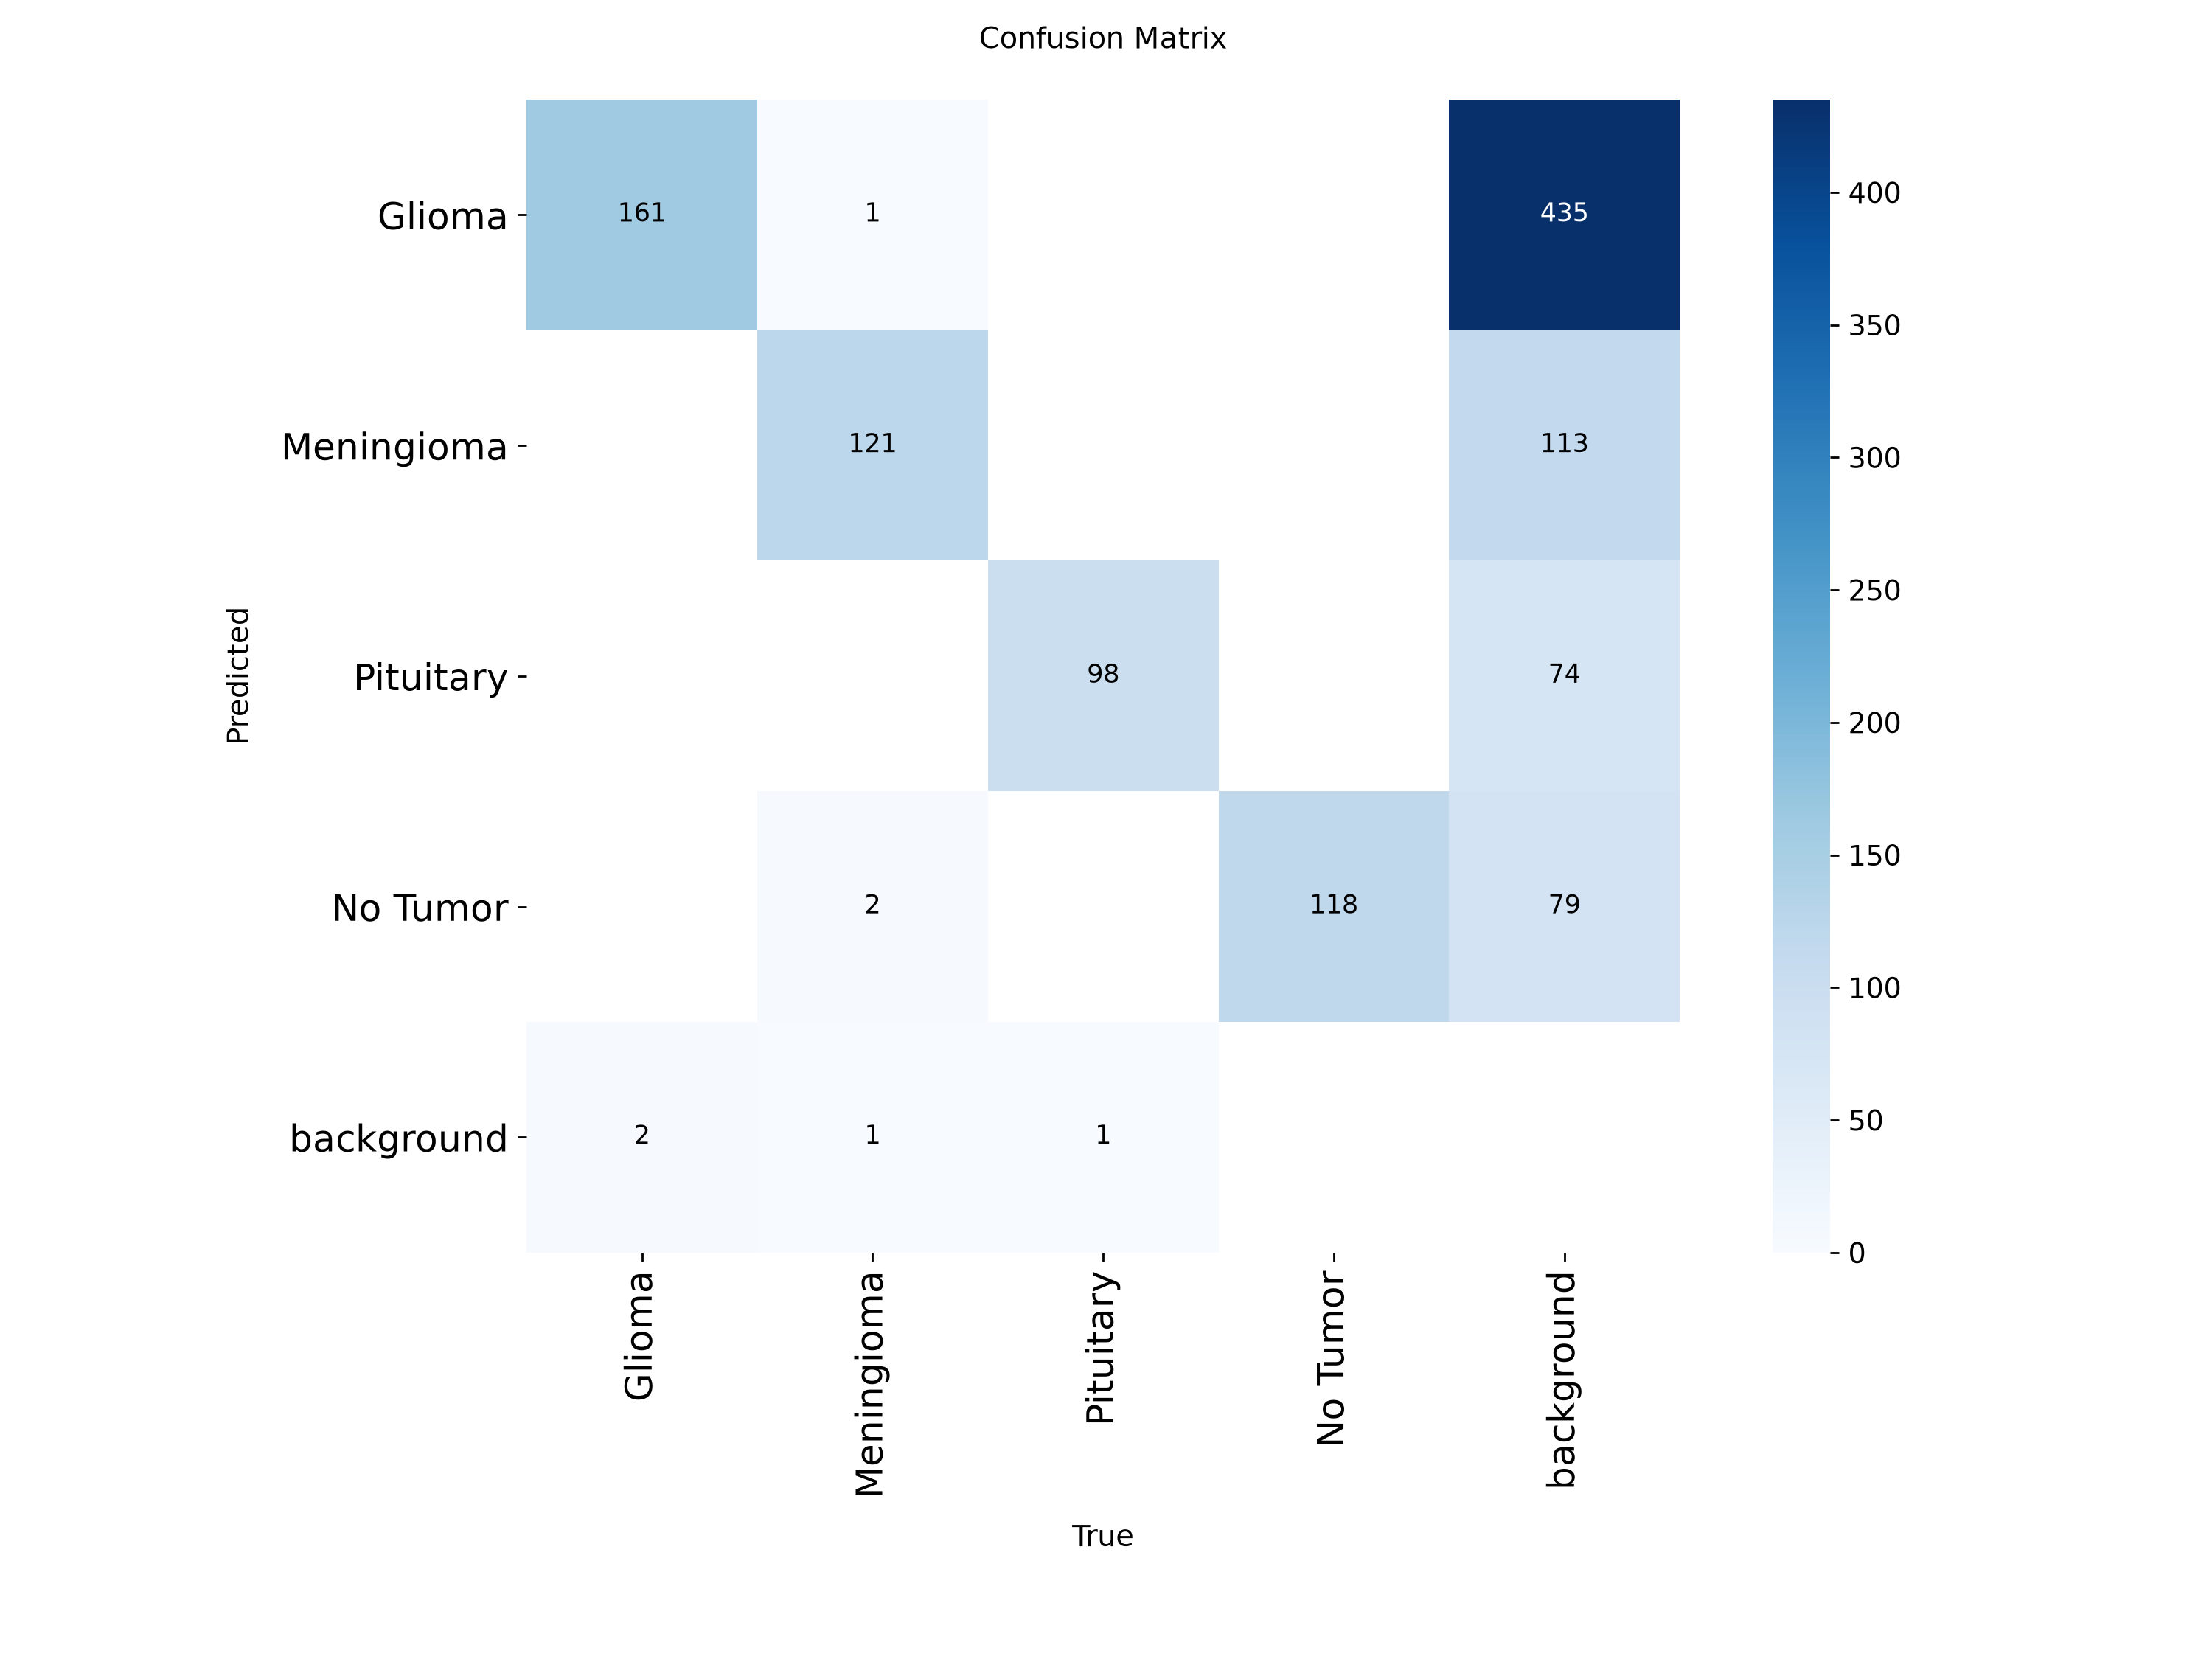

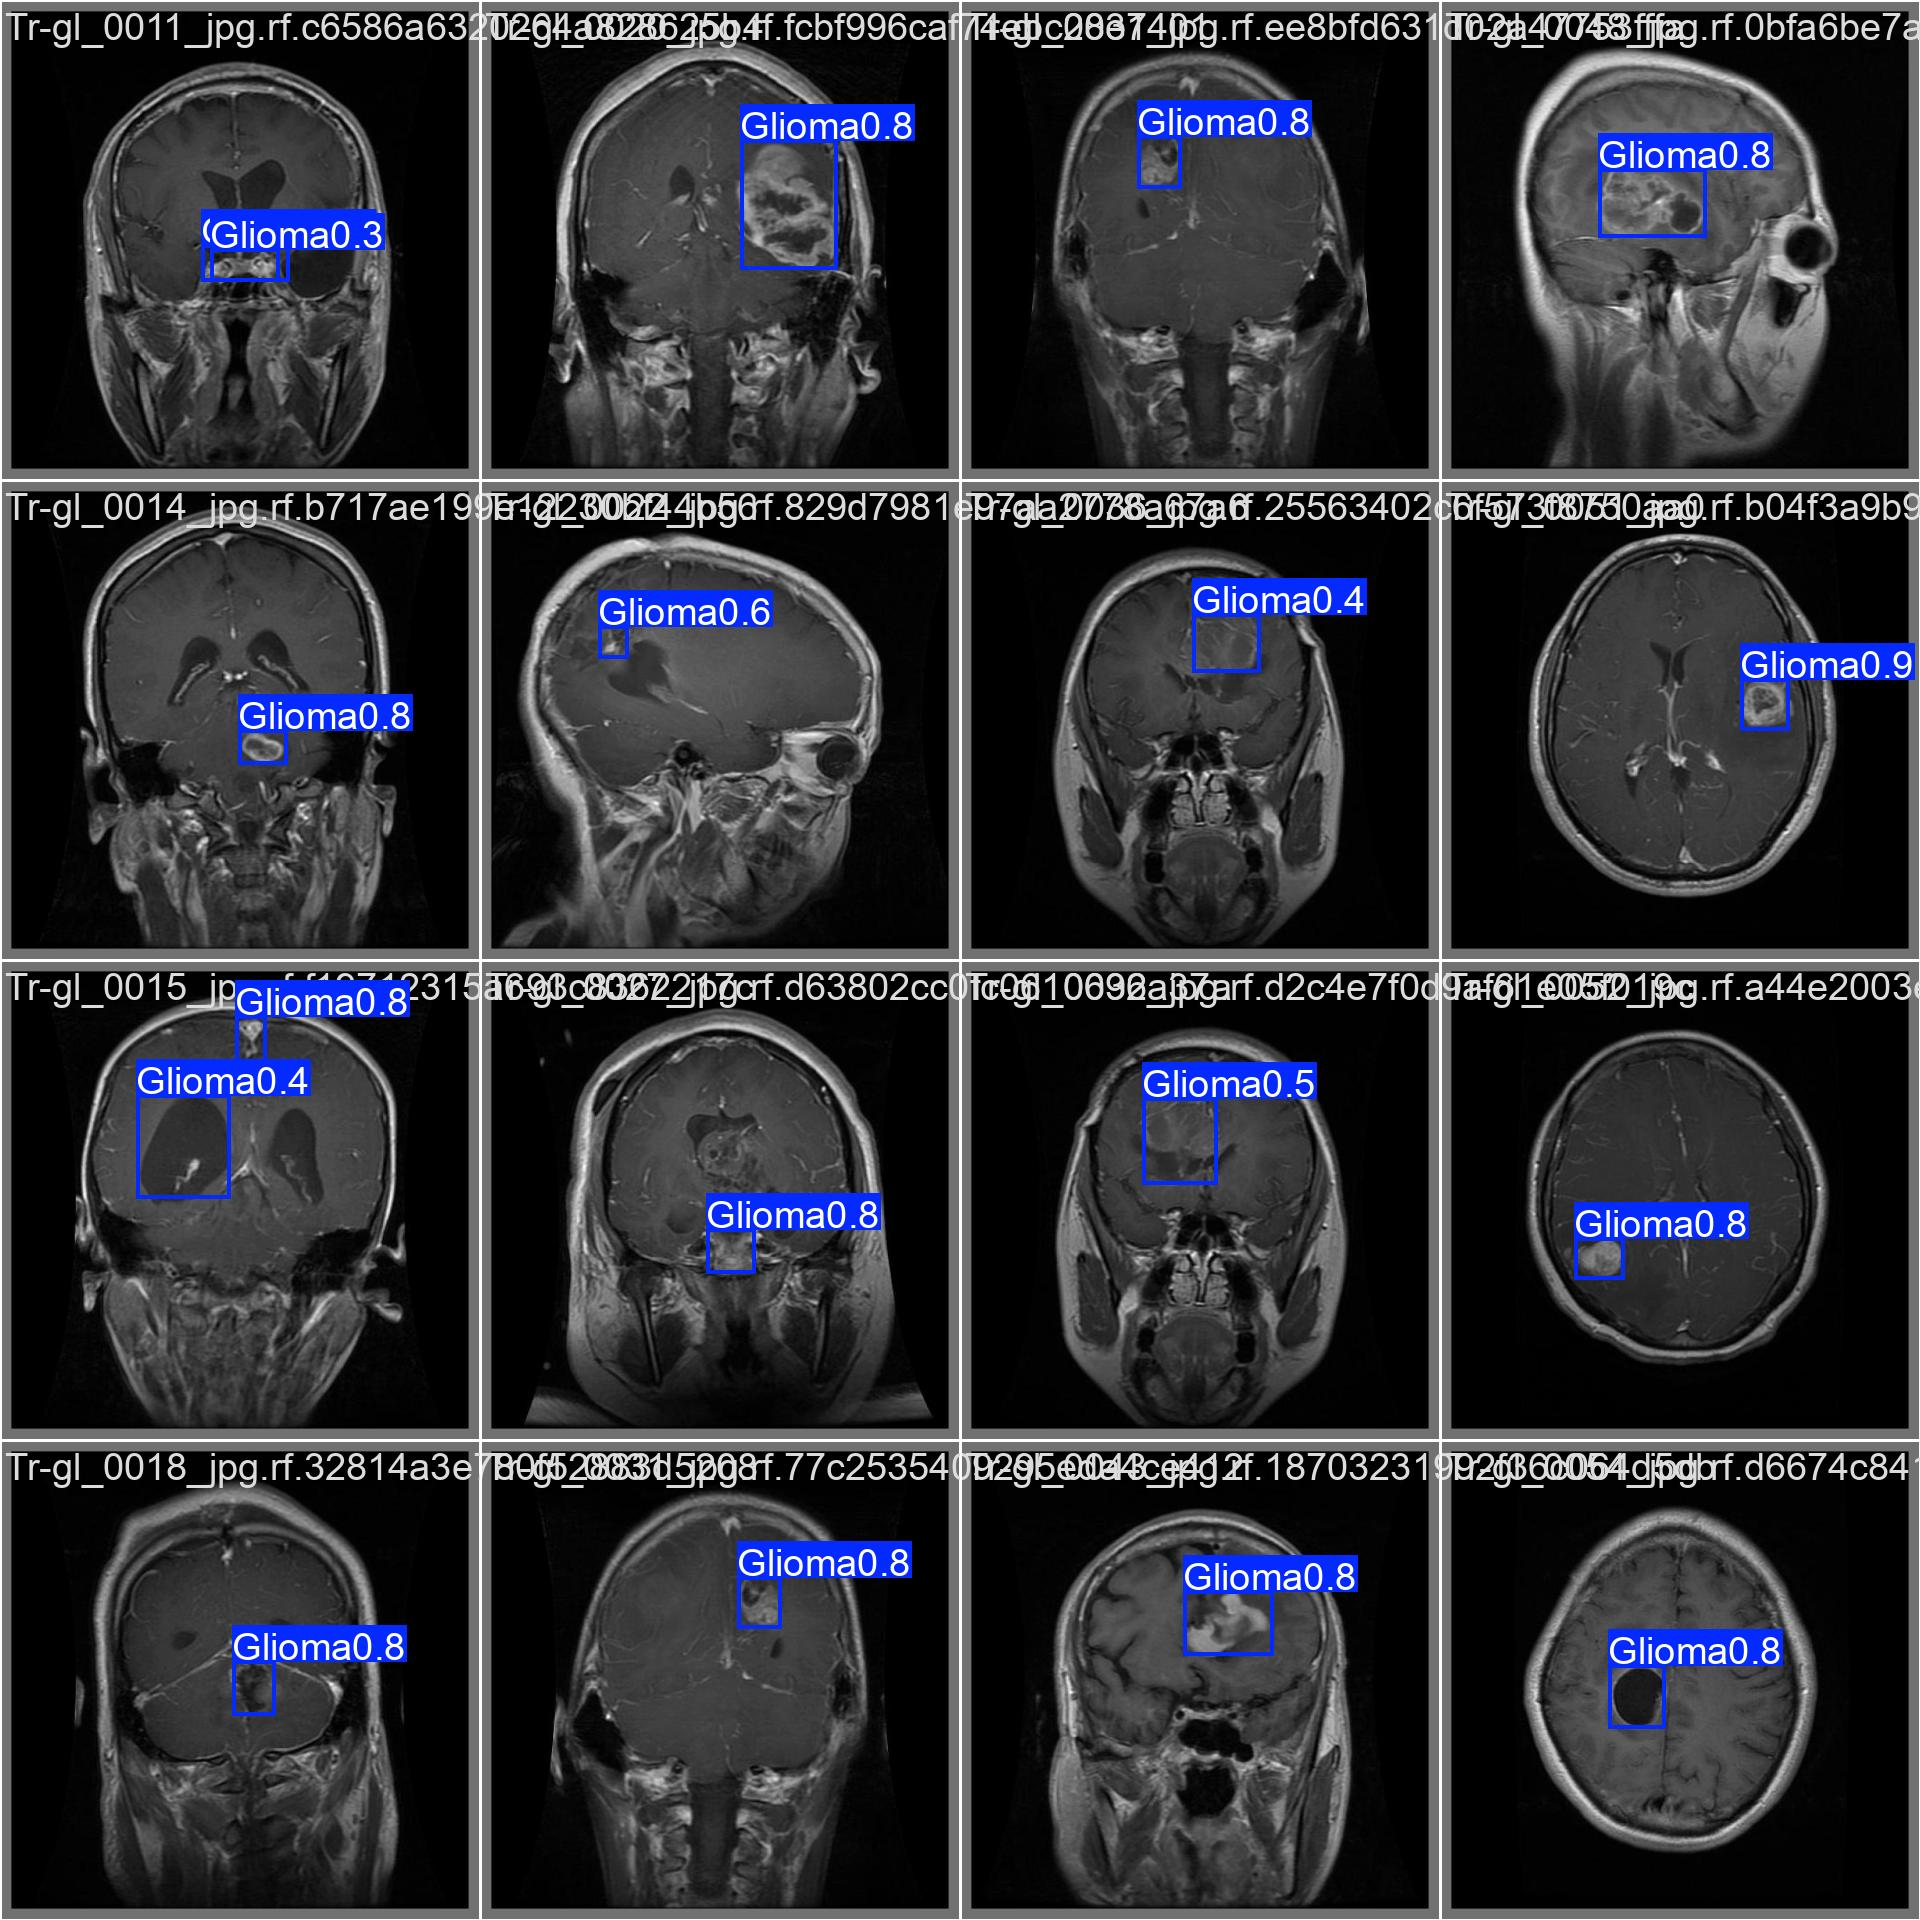

In [17]:
from IPython.display import Image, display

RUN_DIR = Path('./runs/custom_yolo11').resolve()

for fname in ['results.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']:
    path = RUN_DIR / fname
    if path.exists():
        display(Image(filename=str(path), width=800))

## 7. Evaluasi pada validation set

In [7]:
best_model = YOLO(str(RUN_DIR / 'weights' / 'best.pt'))
metrics = best_model.val(data=str(DATA_YAML), batch=8)

print(f'mAP50    : {metrics.box.map50:.4f}')
print(f'mAP50-95 : {metrics.box.map:.4f}')
print(f'Precision: {metrics.box.mp:.4f}')
print(f'Recall   : {metrics.box.mr:.4f}')

Ultralytics 8.4.187 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 79.3±42.0 MB/s, size: 31.3 KB)
val: Scanning /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/labels/val.cache... 502 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 502/502 191.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 4.3it/s 14.7s<0.1s
                   all        502        505      0.942       0.93      0.962      0.589
                Glioma        161        163      0.926      0.916      0.956      0.614
            Meningioma        124        125      0.966      0.911      0.961      0.553
             Pituitary         99         99      0.916      0.919      0.941      0.686
              No Tumor        118        118      0.9

## 8. Inferensi pada gambar baru


image 1/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0011_jpg.rf.c6586a6320264a828625b45ba88fabac.jpg: 640x640 2 Gliomas, 158.7ms
image 2/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0014_jpg.rf.b717ae199e12230bf44b56eba9d741b1.jpg: 640x640 1 Glioma, 10.6ms
image 3/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0015_jpg.rf.f19712315a693c8362217ca980843f70.jpg: 640x640 2 Gliomas, 10.5ms
image 4/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0018_jpg.rf.32814a3e780f52883d520898ecedfb4c.jpg: 640x640 1 Glioma, 10.6ms
image 5/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0020_jpg.rf.fcbf996caf74ebc28e7401df1dd06f7f.jpg: 640x640 1 Glioma, 10.6ms
image 6/502 /home/darklighs/Documents/yolo-training/datasets/MRI-Tumor-Dataset/images/val/Tr-gl_0022_jpg.rf.829d7981e97aa2778a67a60119cf4d9d.

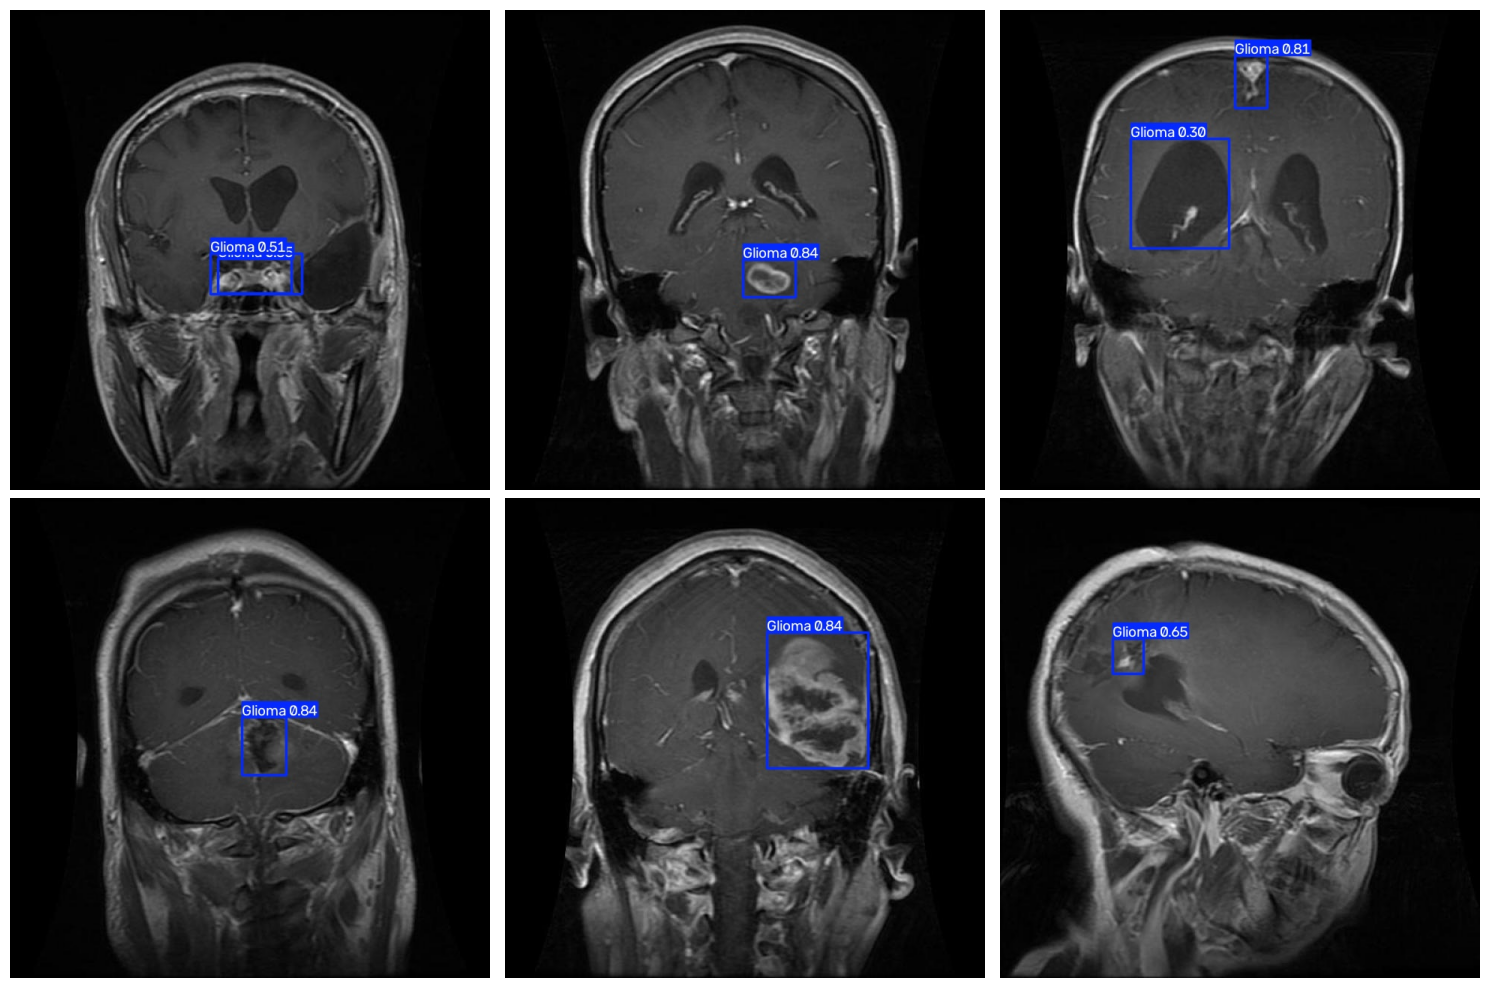

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Ganti dengan folder atau file gambar uji kamu
SOURCE = DATASET_DIR / 'images' / 'val'

best_model.predict(
    source=str(SOURCE),
    conf=0.25,
    save=True,
    project=str(Path('./runs').resolve()),
    name='predict',
    exist_ok=True,
)

files = sorted(Path('./runs/predict').glob('*.jpg'))[:6]
plt.figure(figsize=(15, 10))
for i, f in enumerate(files):
    plt.subplot(2, 3, i + 1)
    plt.imshow(mpimg.imread(f))
    plt.axis('off')
plt.tight_layout()
plt.show()

## 9. Export model (opsional)

Bobot terbaik ada di `runs/custom_yolo11/weights/best.pt`. Export ke ONNX berguna untuk deployment, atau gunakan `format='engine'` untuk TensorRT jika terpasang.

In [ ]:
best_model.export(format='onnx')